# Labeled arrays and regional selection

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/05-labelled-arrays.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/05-labelled-arrays.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `0f1d52f973869ec9c64c8076da3d7928ce50c8b87d404a1f00f1af30aa159644`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Labeled arrays and regional selection

**Lesson 05 · Original synthetic data · Independent educational project**

## Objectives

Use xarray dimensions and units; avoid positional indexing mistakes.

[Previous](04-validation.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/05-labelled-arrays.ipynb) · [Next](06-area-means.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=05-labelled-arrays.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

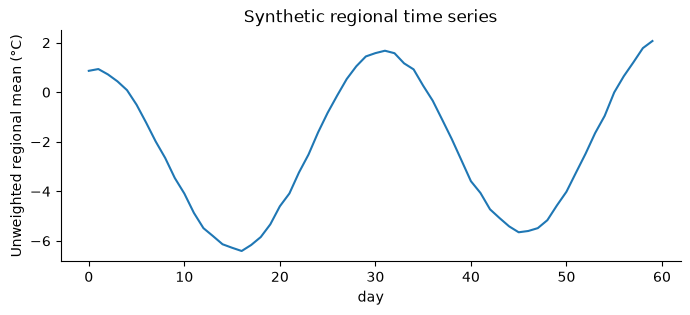

{'units': 'K', 'provenance': 'Original synthetic teaching data; not observations or DestinE model output'}


In [2]:
import xarray as xr
cube = lab.synthetic_cube()
da = xr.DataArray(cube["temperature"], dims=("day", "latitude", "longitude"),
                  coords={"day": cube["time"], "latitude": cube["lat"], "longitude": cube["lon"]},
                  name="temperature", attrs={"units": "K", "provenance": lab.PROVENANCE})
region = da.sel(latitude=slice(30, 60), longitude=slice(-20, 40))
regional = region.mean(("latitude", "longitude")) - 273.15
assert regional.dims == ("day",)
assert region.sizes["latitude"] < da.sizes["latitude"]
fig, ax = plt.subplots(figsize=(8, 3))
regional.plot(ax=ax)
ax.set(ylabel="Unweighted regional mean (°C)", title="Synthetic regional time series")
plt.show()
print(da.attrs)

## Exercise

Transpose the array before selecting the same region. Verify named-dimension calculations still agree.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Labels reduce ambiguity. An arithmetic regional mean is not automatically area weighted; the next lesson addresses that distinction.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://docs.xarray.dev/en/stable/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).